# Análisis de Espacios de Color en Visión por Computadora (OpenCV)
Este cuaderno demuestra cómo se comportan diferentes espacios de color (BGR, HSV, YCrCb y LAB) al intentar segmentar o filtrar un objeto basado en su color.

El objetivo es aislar el color verde de un cubo, aplicando un umbral (threshold) de tolerancia para evaluar qué espacio de color es más resistente a los cambios de iluminación.

In [ ]:
%pip install opencv-python 

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Configuración para que los gráficos de matplotlib se vean más grandes en el cuaderno
plt.rcParams['figure.figsize'] = (15, 10)

## Fase 1: Carga de imágenes y Conversión de Espacios
Leemos las imágenes de entrada (asegúrate de que `cube1.png` y `cube8.png` estén en el mismo directorio que este cuaderno). Luego, transformamos la imagen iluminada desde el formato estándar BGR de OpenCV hacia los modelos LAB, YCrCb y HSV.

In [2]:
# Carga de imágenes (cube1 = iluminada, cube8 = oscura)
bright = cv2.imread('cube1.png')
dark = cv2.imread('cube8.png')

# Conversión de la imagen iluminada a diferentes espacios de color
brightLAB = cv2.cvtColor(bright, cv2.COLOR_BGR2LAB)
darkLAB = cv2.cvtColor(dark, cv2.COLOR_BGR2LAB)

brightYCB = cv2.cvtColor(bright, cv2.COLOR_BGR2YCrCb)
darkYCB = cv2.cvtColor(dark, cv2.COLOR_BGR2YCrCb)

brightHSV = cv2.cvtColor(bright, cv2.COLOR_BGR2HSV)
darkHSV = cv2.cvtColor(dark, cv2.COLOR_BGR2HSV)

## Fase 2: Definición del Color Objetivo y Tolerancia
Definimos el color que queremos extraer en formato BGR. En este caso, un tono verde: `[40, 158, 16]`. 
También definimos un margen de error o `thresh` de 40. Esto significa que buscaremos colores que estén hasta 40 unidades por encima o por debajo de nuestro verde objetivo para abarcar sus variaciones de luz.

In [3]:
# Color verde objetivo y umbral de tolerancia
bgr = [40, 158, 16]
thresh = 40

## Fase 3: Cálculo de Máscaras (Masking)
Para aplicar el filtro, necesitamos establecer los límites inferior y superior por cada espacio de color. 
El proceso es:
1. Convertir nuestro color objetivo (BGR) al espacio correspondiente (HSV, LAB, etc.).
2. Sumar y restar el `thresh` para crear el rango.
3. Usar `cv2.inRange()` para crear la máscara binaria (blanco donde hay verde, negro en el resto).
4. Usar `cv2.bitwise_and()` para recortar la imagen original usando la máscara.

In [4]:
# ---------------- BGR ----------------
minBGR = np.array([bgr[0] - thresh, bgr[1] - thresh, bgr[2] - thresh])
maxBGR = np.array([bgr[0] + thresh, bgr[1] + thresh, bgr[2] + thresh])

maskBGR = cv2.inRange(bright, minBGR, maxBGR)
resultBGR = cv2.bitwise_and(bright, bright, mask=maskBGR)

# ---------------- HSV ----------------
# Convertimos el array 1D a 3D, transformamos a HSV y tomamos el valor resultante
hsv = cv2.cvtColor(np.uint8([[bgr]]), cv2.COLOR_BGR2HSV)[0][0]

minHSV = np.array([hsv[0] - thresh, hsv[1] - thresh, hsv[2] - thresh])
maxHSV = np.array([hsv[0] + thresh, hsv[1] + thresh, hsv[2] + thresh])

maskHSV = cv2.inRange(brightHSV, minHSV, maxHSV)
resultHSV = cv2.bitwise_and(brightHSV, brightHSV, mask=maskHSV)

# ---------------- YCrCb ----------------
ycb = cv2.cvtColor(np.uint8([[bgr]]), cv2.COLOR_BGR2YCrCb)[0][0]

minYCB = np.array([ycb[0] - thresh, ycb[1] - thresh, ycb[2] - thresh])
maxYCB = np.array([ycb[0] + thresh, ycb[1] + thresh, ycb[2] + thresh])

maskYCB = cv2.inRange(brightYCB, minYCB, maxYCB)
resultYCB = cv2.bitwise_and(brightYCB, brightYCB, mask=maskYCB)

# ---------------- LAB ----------------
lab = cv2.cvtColor(np.uint8([[bgr]]), cv2.COLOR_BGR2LAB)[0][0]

minLAB = np.array([lab[0] - thresh, lab[1] - thresh, lab[2] - thresh])
maxLAB = np.array([lab[0] + thresh, lab[1] + thresh, lab[2] + thresh])

maskLAB = cv2.inRange(brightLAB, minLAB, maxLAB)
resultLAB = cv2.bitwise_and(brightLAB, brightLAB, mask=maskLAB)

C:\Users\MSI KATANA\AppData\Local\Temp\ipykernel_27472\1239142852.py:13: RuntimeWarning: overflow encountered in scalar add
  maxHSV = np.array([hsv[0] + thresh, hsv[1] + thresh, hsv[2] + thresh])


## Fase 4: Visualización de Resultados Integrada
Para visualizar correctamente las imágenes dentro del cuaderno, usamos `matplotlib`.
*Nota crítica:* OpenCV lee las imágenes en formato **BGR**, pero matplotlib las renderiza esperando formato **RGB**. Si no convertimos los resultados de vuelta a RGB antes de imprimirlos, los colores verde y rojo se verán invertidos en la pantalla.

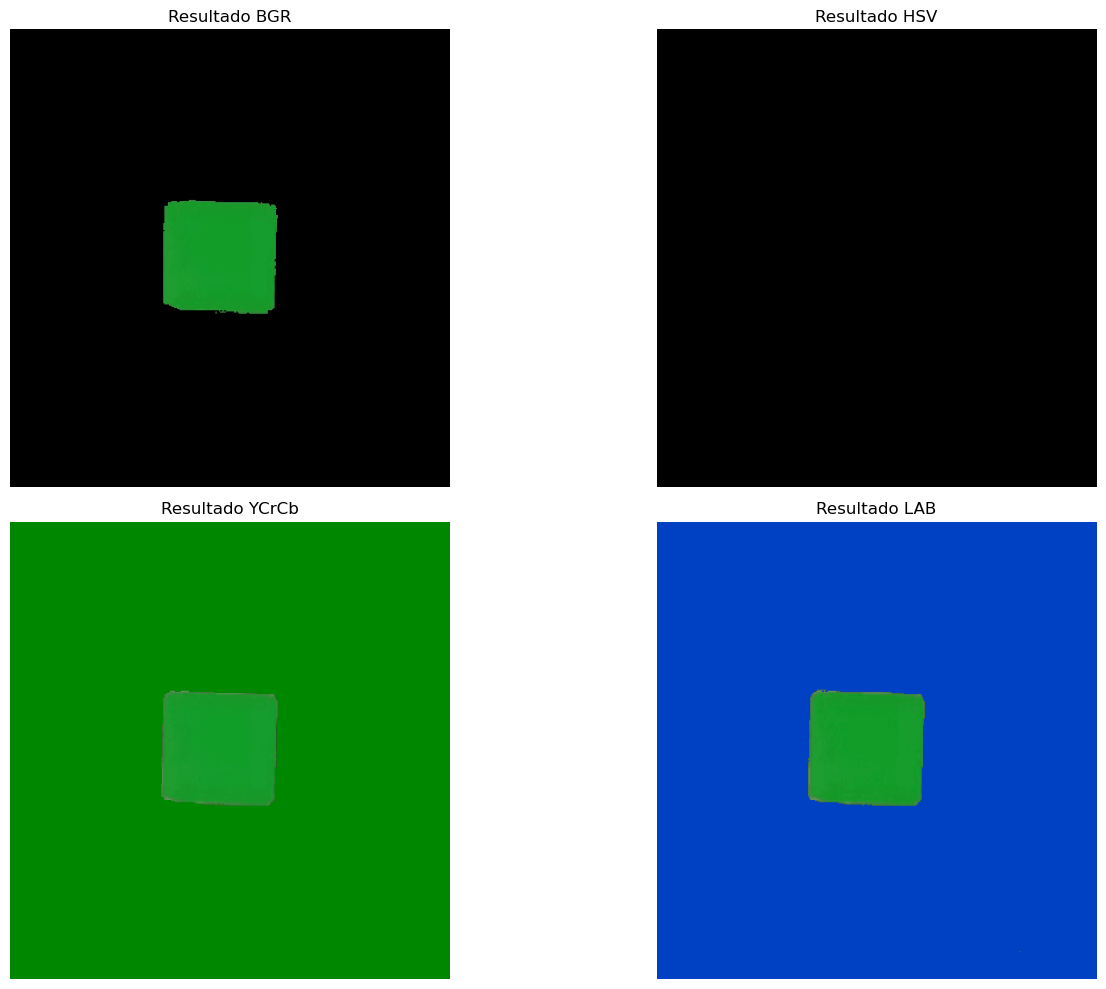

In [5]:
# Convertimos los resultados de BGR a RGB para que matplotlib los renderice con los colores correctos
resBGR_rgb = cv2.cvtColor(resultBGR, cv2.COLOR_BGR2RGB)
resHSV_rgb = cv2.cvtColor(resultHSV, cv2.COLOR_HSV2RGB)
resYCB_rgb = cv2.cvtColor(resultYCB, cv2.COLOR_YCrCb2RGB)
resLAB_rgb = cv2.cvtColor(resultLAB, cv2.COLOR_LAB2RGB)

# Configuramos una grilla de 2x2 para comparar los 4 resultados
fig, axs = plt.subplots(2, 2)

axs[0, 0].imshow(resBGR_rgb)
axs[0, 0].set_title('Resultado BGR')
axs[0, 0].axis('off')

axs[0, 1].imshow(resHSV_rgb)
axs[0, 1].set_title('Resultado HSV')
axs[0, 1].axis('off')

axs[1, 0].imshow(resYCB_rgb)
axs[1, 0].set_title('Resultado YCrCb')
axs[1, 0].axis('off')

axs[1, 1].imshow(resLAB_rgb)
axs[1, 1].set_title('Resultado LAB')
axs[1, 1].axis('off')

plt.tight_layout()
plt.show()

## Fase 5: Análisis de Distribución de Color (Density Plots)
En lugar de adivinar los umbrales de color, la mejor práctica es analizar cómo se distribuyen los píxeles de un color específico a través de múltiples imágenes bajo diferentes condiciones de iluminación. 

Para esto, extraeremos los canales de color de varias imágenes recortadas y construiremos un **Histograma 2D (Density Plot)**. Utilizaremos el enfoque vectorizado moderno para mayor eficiencia de memoria.

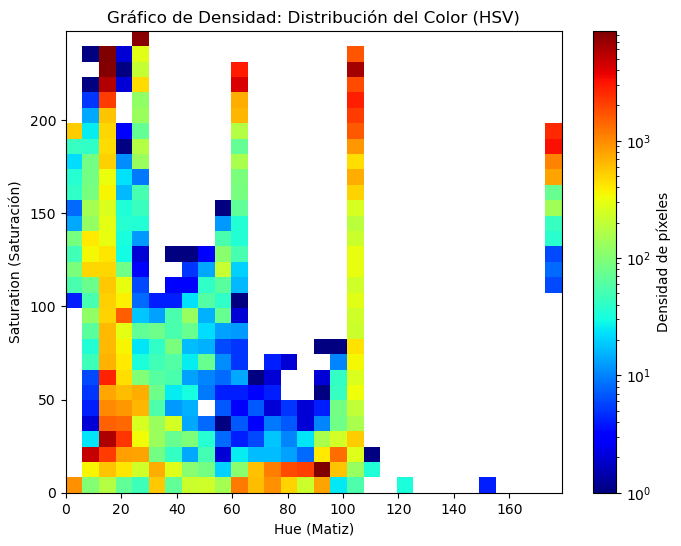

In [10]:
import glob
from matplotlib.colors import LogNorm

# Supongamos que tienes una carpeta 'crops' con varias fotos solo de la cara amarilla del cubo
# files = glob.glob('crops/yellow_*.png') 
# Para este ejemplo, simularemos la lista con nuestra imagen original
files = ['cube1.png'] 

# 1. Cargar imágenes y convertirlas directamente a HSV
images = [cv2.imread(path) for path in files]
space_images = [cv2.cvtColor(image, cv2.COLOR_BGR2HSV) for image in images]

# 2. Aplanar y concatenar todos los píxeles en una sola matriz N x 3 (Método optimizado 2026)
pixels = np.concatenate([image.reshape(-1, 3) for image in space_images], axis=0)

# 3. Extraer los canales de Matiz (Hue) y Saturación
hue = pixels[:, 0]
saturation = pixels[:, 1]

# 4. Graficar el Histograma 2D
plt.figure(figsize=(8, 6))
plt.hist2d(hue, saturation, bins=30, norm=LogNorm(), cmap='jet')
plt.colorbar(label='Densidad de píxeles')
plt.xlabel('Hue (Matiz)')
plt.ylabel('Saturation (Saturación)')
plt.title('Gráfico de Densidad: Distribución del Color (HSV)')
plt.show()

**Observaciones del Gráfico de Densidad:**
*   **¿Por qué elegir HSV?** En los gráficos de densidad BGR, los valores estallan en todas direcciones cuando cambia la luz. En HSV, la información del color absoluto recae casi por completo en un solo canal (el *Hue*), creando gráficas compactas. Tienes que ajustar una sola perilla en lugar de tres.
*   *Nota de producción:* El matiz (Hue) es poco confiable cuando se acerca al gris. Si la saturación es muy baja, un pequeño ruido en el sensor produce saltos enormes en el matiz.

## Fase 6: Segmentación Robusta y el Problema del "Hue Circular"
En OpenCV (formato de 8 bits), el canal *Hue* va de 0 a 179. El problema ocurre con colores como el **Rojo**, que se encuentra justo en el límite matemático: puede tener valores cercanos a 170 o cercanos a 10. 

Si definimos un rango que cruza este límite (ej. `lower=170`, `upper=10`), la función `cv2.inRange` fallará a menos que dividamos la máscara en dos mitades y las unamos.

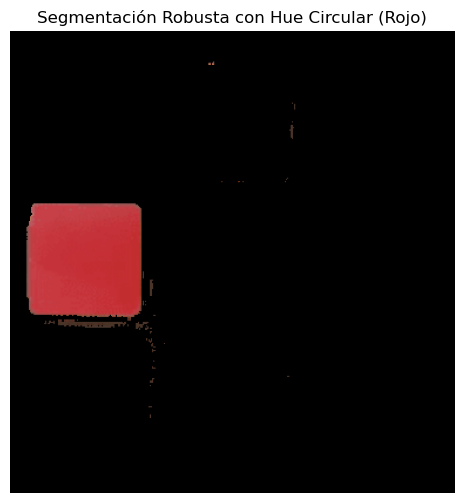

In [9]:
# Función robusta para segmentar colores en HSV teniendo en cuenta el límite circular
def segmentar_color_robusto(image_bgr, lower_hue, upper_hue, min_s=80, min_v=40, max_s=255, max_v=255):
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    
    # Si el límite inferior es mayor que el superior (ej. Rojo cruzando el umbral de 179 a 0)
    if lower_hue > upper_hue:
        # Primera mitad: de lower_hue hasta el máximo (179)
        high_half = cv2.inRange(hsv, 
                                np.array([lower_hue, min_s, min_v], dtype=np.int32), 
                                np.array([179, max_s, max_v], dtype=np.int32))
        # Segunda mitad: de 0 hasta upper_hue
        low_half = cv2.inRange(hsv, 
                               np.array([0, min_s, min_v], dtype=np.int32), 
                               np.array([upper_hue, max_s, max_v], dtype=np.int32))
        
        # Unir ambas máscaras
        mask = cv2.bitwise_or(high_half, low_half)
    else:
        # Comportamiento normal (ej. Verde, Azul)
        mask = cv2.inRange(hsv, 
                           np.array([lower_hue, min_s, min_v], dtype=np.int32), 
                           np.array([upper_hue, max_s, max_v], dtype=np.int32))
    
    # IMPORTANTE: La máscara se calcula en HSV, pero se aplica sobre la imagen BGR original
    # para no distorsionar los colores resultantes al mostrarlos.
    result_bgr = cv2.bitwise_and(image_bgr, image_bgr, mask=mask)
    return result_bgr

# Prueba del algoritmo con un cruce de frontera (Ejemplo: Rojo)
resultado_rojo = segmentar_color_robusto(bright, lower_hue=170, upper_hue=10)

# Visualizar el resultado final
resultado_rojo_rgb = cv2.cvtColor(resultado_rojo, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 6))
plt.imshow(resultado_rojo_rgb)
plt.title('Segmentación Robusta con Hue Circular (Rojo)')
plt.axis('off')
plt.show()

Practica

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split


# 1. Cargar el archivo .ndjson
df_raw = pd.read_json('sku110k.ndjson', lines=True)

# Filtrar la fila de metadatos (donde 'type' es 'dataset' o 'file' es nulo)
df_images = df_raw[df_raw['type'] == 'image'].copy()

# 2. Aplanar los datos (Data Wrangling)
# En este dataset, 'annotations' es un diccionario que contiene la clave 'boxes' (una lista de listas)
# Extraemos 'boxes' de cada diccionario de annotations
def extraer_boxes(x):
    if isinstance(x, dict) and 'boxes' in x:
        return x['boxes']
    return []

df_images['boxes'] = df_images['annotations'].apply(extraer_boxes)

# explode() crea una nueva fila por cada caja (bounding box) asociada a la imagen
df = df_images.explode('boxes').reset_index(drop=True)

# Extraemos los elementos de cada box (por ejemplo, [class_id, x, y, w, h]) a columnas independientes
# Si hay cajas válidas, las convertimos en columnas
df_boxes = df['boxes'].apply(lambda x: pd.Series(x) if isinstance(x, list) else pd.Series([None]*5))
df_boxes.columns = ['class_id', 'x_center', 'y_center', 'box_width', 'box_height']
df = pd.concat([df.drop(['annotations', 'boxes'], axis=1), df_boxes], axis=1)

# 3. Análisis de Densidad para Estratificación
# Contamos cuántos productos (cajas) tiene cada imagen ('file')
conteo_productos = df['file'].value_counts().rename_axis('file').reset_index(name='box_count')

# Discretizamos en Baja, Media, Alta densidad
conteo_productos['densidad_estante'] = pd.qcut(conteo_productos['box_count'], q=3, labels=['Baja', 'Media', 'Alta'])

# 4. Muestreo Estratificado (Extraer 600 imágenes manteniendo la proporción de densidad)
muestreo_total, _ = train_test_split(
    conteo_productos,
    train_size=600,
    stratify=conteo_productos['densidad_estante'],
    random_state=42
)

# 5. Dividir en Entrenamiento (500) y Validación (100)
train_images, val_images = train_test_split(
    muestreo_total,
    train_size=500,
    stratify=muestreo_total['densidad_estante'],
    random_state=42
)

# 6. Filtrar el DataFrame aplanado con nuestra muestra seleccionada
df_train = df[df['file'].isin(train_images['file'])]
df_val = df[df['file'].isin(val_images['file'])]

print(f"Dataset de Entrenamiento: {len(train_images)} imágenes, {len(df_train)} productos a detectar.")
print(f"Dataset de Validación: {len(val_images)} imágenes, {len(df_val)} productos a detectar.")
# Imprime todos los nombres de las columnas que tiene tu archivo
print(df_images.columns)

# Muestra la primera fila para ver qué datos contiene cada columna
display(df_images.head(1))

Dataset de Entrenamiento: 500 imágenes, 74038 productos a detectar.
Dataset de Validación: 100 imágenes, 14738 productos a detectar.
Index(['type', 'task', 'name', 'description', 'bytes', 'url', 'class_names',
       'version', 'created_at', 'updated_at', 'file', 'width', 'height',
       'split', 'annotations', 'boxes'],
      dtype='object')


,type,task,name,description,bytes,url,class_names,version,created_at,updated_at,file,width,height,split,annotations,boxes
1,image,NaN,NaN,NaN,NaN,https://cdn.ul.run/eu/i/000fab79e49c5e79040d21...,NaN,NaN,NaT,NaT,test_2116.jpg,2448.0,3264.0,test,"{'boxes': [[0, 0.6893100000000001, 0.4943, 0.0...","[[0, 0.6893100000000001, 0.4943, 0.04367, 0.06..."


Descargando imagen desde: https://cdn.ul.run/eu/i/6cb6fdf53c0b18ab4ee9f98a90d98501.jpg?Expires=1792310400&KeyName=key-v1&Signature=GctKPUHCS6L39XTVtqGAjZSHkXI


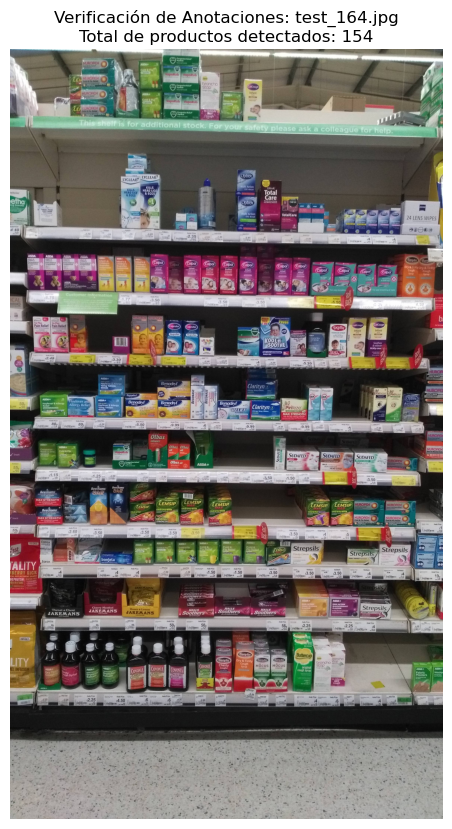

In [8]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import urllib.request

# 1. Seleccionar una imagen aleatoria del set de entrenamiento
imagen_muestra = df_train['file'].sample(1).values[0]
cajas_muestra = df_train[df_train['file'] == imagen_muestra]

# 2. Extraer la URL directa de la imagen desde df_images
url_img = df_images[df_images['file'] == imagen_muestra]['url'].values[0]
print(f"Descargando imagen desde: {url_img}")

# 3. Descargar la imagen a la memoria RAM y decodificarla
req = urllib.request.urlopen(url_img)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_COLOR)

if img is None:
    raise ValueError("CRÍTICO: No se pudo descargar la imagen. Verifica tu conexión a internet.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Obtener dimensiones reales de la imagen para des-normalizar las coordenadas
h_img, w_img, _ = img_rgb.shape

# 4. Dibujar las cajas
for _, fila in cajas_muestra.iterrows():
    # Extraemos las coordenadas (que van de 0.0 a 1.0)
    x_c_norm = float(fila['x_center'])
    y_c_norm = float(fila['y_center'])
    w_norm = float(fila['width'])
    h_norm = float(fila['height'])
    
    # Multiplicamos por el ancho (w_img) y alto (h_img) real para obtener los píxeles
    x_c = x_c_norm * w_img
    y_c = y_c_norm * h_img
    w = w_norm * w_img
    h = h_norm * h_img
    
    # Calculamos vértices en enteros para OpenCV
    x1 = int(x_c - (w / 2))
    y1 = int(y_c - (h / 2))
    x2 = int(x_c + (w / 2))
    y2 = int(y_c + (h / 2))
    
    cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (255, 0, 0), 3)

# 5. Mostrar el resultado
plt.figure(figsize=(15, 10))
plt.imshow(img_rgb)
plt.title(f"Verificación de Anotaciones: {imagen_muestra}\nTotal de productos detectados: {len(cajas_muestra)}")
plt.axis('off')
plt.show()

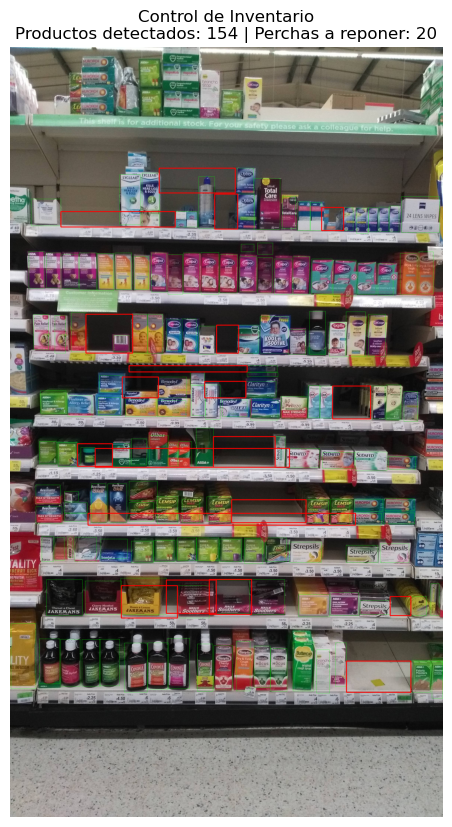

In [9]:
import pandas as pd

# 1. Crear un DataFrame con las coordenadas absolutas en píxeles
cajas = cajas_muestra.copy()

# Des-normalizar para obtener píxeles reales
cajas['x_c_abs'] = cajas['x_center'] * w_img
cajas['y_c_abs'] = cajas['y_center'] * h_img
cajas['w_abs'] = cajas['box_width'] * w_img
cajas['h_abs'] = cajas['box_height'] * h_img

cajas['x1'] = cajas['x_c_abs'] - (cajas['w_abs'] / 2)
cajas['x2'] = cajas['x_c_abs'] + (cajas['w_abs'] / 2)
cajas['y1'] = cajas['y_c_abs'] - (cajas['h_abs'] / 2)
cajas['y2'] = cajas['y_c_abs'] + (cajas['h_abs'] / 2)

# 2. Agrupar los productos por "Estantes" (Clustering básico en el eje Y)
# Dividimos el eje vertical en franjas. Si dos productos tienen un Y central 
# dentro de la misma franja, asumimos que están en la misma percha.
TOLERANCIA_VERTICAL = 150  # Ajustable: Píxeles de altura aproximada de una percha
cajas['percha_id'] = (cajas['y_c_abs'] / TOLERANCIA_VERTICAL).round().astype(int)

# Ordenar los productos: Primero por estante (arriba hacia abajo), luego por posición X (izq a der)
cajas = cajas.sort_values(by=['percha_id', 'x_c_abs'])

# 3. Detección de Espacio Negativo (Huecos)
huecos_vacios = []

# Iteramos estante por estante
for percha, grupo in cajas.groupby('percha_id'):
    prev_x2 = None # Borde derecho del producto anterior
    
    for _, fila in grupo.iterrows():
        if prev_x2 is not None:
            # Calcular la distancia entre el producto anterior y el actual
            distancia_vacia = fila['x1'] - prev_x2
            
            # REGLA DE NEGOCIO: Alta Precisión
            # Solo alertar si el hueco es más grande que el 90% del ancho del producto actual.
            # Evita enviar empleados por separaciones de un par de centímetros.
            umbral_minimo = fila['w_abs'] * 0.9 
            
            if distancia_vacia > umbral_minimo:
                huecos_vacios.append({
                    'x1': int(prev_x2),
                    'y1': int(fila['y1']),
                    'x2': int(fila['x1']),
                    'y2': int(fila['y2'])
                })
        
        # Actualizar el borde derecho para la siguiente iteración
        prev_x2 = fila['x2']

# 4. Visualización del resultado estratégico
img_resultado = img_rgb.copy()

# Dibujar los productos detectados en verde tenue (contexto)
for _, fila in cajas.iterrows():
    cv2.rectangle(img_resultado, (int(fila['x1']), int(fila['y1'])), (int(fila['x2']), int(fila['y2'])), (0, 255, 0), 1)

# Dibujar las PERCHAS VACÍAS en rojo grueso (La alerta real para el negocio)
for hueco in huecos_vacios:
    cv2.rectangle(img_resultado, (hueco['x1'], hueco['y1']), (hueco['x2'], hueco['y2']), (255, 0, 0), 4)

plt.figure(figsize=(15, 10))
plt.imshow(img_resultado)
plt.title(f"Control de Inventario\nProductos detectados: {len(cajas)} | Perchas a reponer: {len(huecos_vacios)}")
plt.axis('off')
plt.show()